# TrashNet Waste Classification (6 classes)

Classes: `cardboard, glass, metal, paper, plastic, trash`

**Pipeline:** HF dataset -> exact-duplicate removal (MD5) -> stratified 70/15/15 split (seed 42) -> baseline CNN vs fine-tuned ResNet18 (with / without augmentation) -> metrics + confusion matrix -> failure cases -> confidence-threshold tuning -> latency -> inference script (`predict.py`) -> demo.

**How to run:** Runtime -> GPU (Colab) is recommended. Then run all cells top to bottom (~10-15 min on a T4 GPU). Needs internet (dataset + pretrained ResNet18 weights).

## Architecture

```
Image (any size)
   |  resize 224x224, normalise (ImageNet mean/std)
   v
+-----------------------------+      +--------------------------------------+
| Baseline CNN (from scratch) |      | ResNet18 (ImageNet-pretrained)        |
| 4 x [Conv3x3-BN-ReLU-Pool]  |      | conv1 -> layer1..layer4 -> avgpool    |
| 32-64-128-256 ch, GAP       |      | fc replaced: 512 -> 6                 |
| Dropout 0.3 -> Linear(6)    |      | all layers fine-tuned                 |
+--------------+--------------+      +------------------+-------------------+
               \_______________________  _______________/
                                       v
                          softmax -> class + confidence
                                       v
                  confidence >= threshold ? class : "uncertain"
```

## 1. Setup

In [8]:
!pip install -q datasets scikit-learn matplotlib

In [9]:
import os, time, copy, json, random, hashlib
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from datasets import load_dataset, concatenate_datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

SEED = 42
IMG = 224
BATCH = 32
NUM_WORKERS = 0 if os.name == "nt" else 2

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu128


## 2. Dataset: source, version, images per class

In [10]:
DATASET_ID = "garythung/trashnet"
PARQUET_GLOB = "hf://datasets/garythung/trashnet@refs%2Fconvert%2Fparquet/default/train/*.parquet"

def load_trashnet():
    # The repo's default imagefolder loader can fail ("Invalid string class label trashnet@<hash>"),
    # so we try the auto-converted Parquet version first.
    attempts = [
        ("auto-converted parquet branch", lambda: load_dataset(DATASET_ID, revision="refs/convert/parquet")),
        ("parquet files via hf:// path", lambda: load_dataset("parquet", data_files={"train": PARQUET_GLOB})),
        ("default loader", lambda: load_dataset(DATASET_ID)),
    ]
    for name, fn in attempts:
        try:
            d = fn()
            print("Loaded with:", name)
            return d
        except Exception as e:
            print(f"[{name}] failed: {type(e).__name__}: {str(e)[:200]}")
    raise RuntimeError("Could not load the dataset with any method. Check your internet connection.")

dd = load_trashnet()
print(dd)
raw = concatenate_datasets([dd[k] for k in dd.keys()])

feat = raw.features["label"]
if hasattr(feat, "names"):
    CLASSES = list(feat.names)
    to_idx = lambda v: int(v)
else:                                   # labels stored as plain strings
    CLASSES = sorted(set(raw["label"]))
    to_idx = lambda v: CLASSES.index(v)
print("Classes:", CLASSES)

try:
    from huggingface_hub import HfApi
    revision = HfApi().dataset_info(DATASET_ID).sha
except Exception as e:
    revision = f"unavailable ({e})"

print("\nSource   : https://huggingface.co/datasets/garythung/trashnet (mirror of https://github.com/garythung/trashnet)")
print("HF commit:", revision)
print("Total images in the HF dataset (before cleaning):", len(raw))
raw_counts = Counter(to_idx(v) for v in raw["label"])
for i, c in enumerate(CLASSES):
    print(f"  {c:10s}: {raw_counts[i]}")

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.40GB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/train/0001.parquet: reconstructing file:   0%|          |  0.00B / 1.55GB            

default/train/0001.parquet: downloading bytes:           |  0.00B            

default/train/0002.parquet: reconstructing file:   0%|          |  0.00B /  714MB            

default/train/0002.parquet: downloading bytes:           |  0.00B            

default/train/0003.parquet: reconstructing file:   0%|          |  0.00B / 34.7MB            

default/train/0003.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Loaded with: auto-converted parquet branch
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5054
    })
})
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

Source   : https://huggingface.co/datasets/garythung/trashnet (mirror of https://github.com/garythung/trashnet)
HF commit: 94cd17ebfd6702bf62281d3c89f22ff649815b46
Total images in the HF dataset (before cleaning): 5054
  cardboard : 806
  glass     : 1002
  metal     : 820
  paper     : 1188
  plastic   : 964
  trash     : 274


## 3. Remove duplicate and near-duplicate images

The original TrashNet has 2,527 photos, but this mirror has ~5,050 rows, which suggests every photo is stored twice (an original-resolution copy and a resized copy). Those copies are *not* byte-identical, so an exact hash would miss them and they could end up in both train and test (data leakage).

So we use a **perceptual hash (dHash)**, computed for 4 rotations in case a copy is rotated. Two images whose hashes differ by <= 6 of 64 bits are treated as the same photo, and only one is kept. This is done **before** splitting, and the split cell later re-checks that no near-duplicates cross splits.

In [11]:
from PIL import Image

THR = 6   # max Hamming distance (of 64 bits) for two images to count as "the same photo"

def dhash(pil, size=8):
    g = pil.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int(np.packbits(bits).view(">u8")[0])

_table = np.array([bin(i).count("1") for i in range(65536)], dtype=np.uint8)
def popcount64(x):
    x = x.astype(np.uint64)
    out = np.zeros(x.shape, dtype=np.int64)
    for s in (0, 16, 32, 48):
        out += _table[((x >> np.uint64(s)) & np.uint64(0xFFFF)).astype(np.int64)]
    return out

def dist_to(Hm, i, idxs):
    """Symmetric rotation-aware Hamming distance between image i and each image in idxs."""
    a = popcount64(Hm[idxs] ^ Hm[i, 0]).min(axis=1)                    # i (rot 0) vs j (any rotation)
    b = popcount64(Hm[i][None, :] ^ Hm[idxs, 0][:, None]).min(axis=1)  # j (rot 0) vs i (any rotation)
    return np.minimum(a, b)

# --- pass 1: decode every image once, store a 224x224 copy and its hashes ---
all_imgs, all_labels, rot_hashes, orig_sizes = [], [], [], []
for i in range(len(raw)):
    ex = raw[i]
    img = ex["image"]
    orig_sizes.append(img.size)
    try:
        img.draft("RGB", (512, 512))      # fast JPEG decode at reduced size (no-op for other formats)
    except Exception:
        pass
    img = img.convert("RGB")
    thumb = img.copy(); thumb.thumbnail((256, 256))
    rot_hashes.append([dhash(thumb.rotate(90 * k, expand=True)) for k in range(4)])
    all_imgs.append(img.resize((IMG, IMG)))
    all_labels.append(to_idx(ex["label"]))
    if (i + 1) % 1000 == 0:
        print(f"  processed {i + 1}/{len(raw)}")

print("Original image widths:", Counter("<= 640 px wide" if w <= 640 else "> 640 px wide" for w, h in orig_sizes))

# --- pass 2: group near-duplicates (union-find), keep the first image of each group ---
H = np.array(rot_hashes, dtype=np.uint64)          # shape (N, 4)
N = len(H)
parent = list(range(N))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a

for i in range(N - 1):
    idxs = np.arange(i + 1, N)
    d = dist_to(H, i, idxs)
    for j in idxs[d <= THR]:
        ri, rj = find(i), find(int(j))
        if ri != rj:
            parent[rj] = ri

groups = {}
for i in range(N):
    groups.setdefault(find(i), []).append(i)

keep = sorted(g[0] for g in groups.values())
sizes = Counter(len(g) for g in groups.values())
conflict = sum(1 for g in groups.values() if len({all_labels[k] for k in g}) > 1)

images = [all_imgs[i] for i in keep]
labels = np.array([all_labels[i] for i in keep])
H_kept = H[keep]

print(f"\nImages before: {N} | unique photos kept: {len(keep)} | removed: {N - len(keep)}")
print("Group sizes (images per unique photo):", dict(sorted(sizes.items())))
print(f"Groups whose copies had conflicting labels (first kept): {conflict}")
if len(keep) > 2800:
    print("WARNING: expected about 2,527 unique photos; some duplicates may remain (consider a larger THR).")
del all_imgs

  processed 1000/5054
  processed 2000/5054
  processed 3000/5054
  processed 4000/5054
  processed 5000/5054
Original image widths: Counter({'> 640 px wide': 2527, '<= 640 px wide': 2527})

Images before: 5054 | unique photos kept: 2077 | removed: 2977
Group sizes (images per unique photo): {2: 2026, 4: 47, 6: 1, 8: 1, 10: 1, 790: 1}
Groups whose copies had conflicting labels (first kept): 15


## 4. Class distribution and imbalance

cardboard :  331  (15.9%)
glass     :  417  (20.1%)
metal     :  363  (17.5%)
paper     :  482  (23.2%)
plastic   :  362  (17.4%)
trash     :  122  (5.9%)

Imbalance ratio (largest / smallest class): 3.95


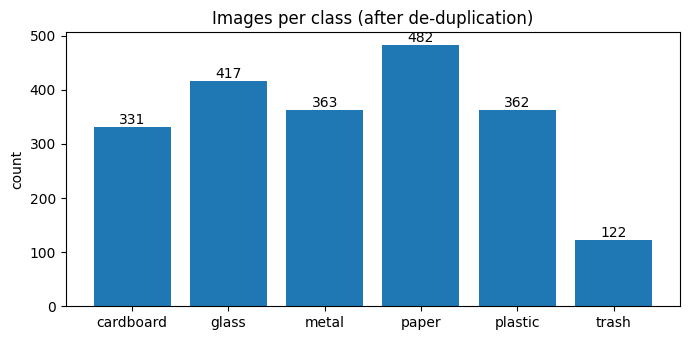

In [12]:
counts = np.bincount(labels, minlength=len(CLASSES))
for c, n in zip(CLASSES, counts):
    print(f"{c:10s}: {n:4d}  ({100*n/len(labels):.1f}%)")
print(f"\nImbalance ratio (largest / smallest class): {counts.max()/counts.min():.2f}")

plt.figure(figsize=(7, 3.5))
bars = plt.bar(CLASSES, counts, color="tab:blue")
plt.bar_label(bars)
plt.title("Images per class (after de-duplication)")
plt.ylabel("count"); plt.tight_layout(); plt.show()

**Imbalance:** `trash` is far smaller than the other classes (roughly 4x fewer than `paper`), so a model can score a decent overall accuracy while doing poorly on `trash`. We therefore (a) use **class-weighted cross-entropy**, (b) use **stratified splits**, and (c) report per-class precision/recall/F1 and macro-F1, not just accuracy.

## 5. Reproducible stratified split (70 / 15 / 15, seed 42)

In [13]:
all_idx = np.arange(len(labels))
train_idx, tmp_idx = train_test_split(all_idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=labels[tmp_idx], random_state=SEED)

# check 1: no index overlap; check 2: no near-duplicate (perceptual hash) across splits
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(labels)

def min_cross_dist(A, B):
    return min(int(dist_to(H_kept, a, B).min()) for a in A)

for name, A, B in [("val vs train", val_idx, train_idx), ("test vs train", test_idx, train_idx), ("test vs val", test_idx, val_idx)]:
    m = min_cross_dist(A, B)
    print(f"closest pair, {name}: Hamming distance {m} (duplicates are <= {THR})")
    assert m > THR, "near-duplicate image found across splits!"
print("No duplicate / near-duplicate images across splits: OK")

print(f"\n{'class':10s} {'train':>6s} {'val':>6s} {'test':>6s}")
for i, c in enumerate(CLASSES):
    print(f"{c:10s} {(labels[train_idx]==i).sum():6d} {(labels[val_idx]==i).sum():6d} {(labels[test_idx]==i).sum():6d}")
print(f"{'TOTAL':10s} {len(train_idx):6d} {len(val_idx):6d} {len(test_idx):6d}")

with open("splits.json", "w") as f:
    json.dump({"seed": SEED, "train": train_idx.tolist(), "val": val_idx.tolist(), "test": test_idx.tolist(),
               "classes": CLASSES}, f)

closest pair, val vs train: Hamming distance 7 (duplicates are <= 6)
closest pair, test vs train: Hamming distance 7 (duplicates are <= 6)
closest pair, test vs val: Hamming distance 7 (duplicates are <= 6)
No duplicate / near-duplicate images across splits: OK

class       train    val   test
cardboard     232     50     49
glass         292     63     62
metal         254     54     55
paper         337     72     73
plastic       253     54     55
trash          85     19     18
TOTAL        1453    312    312


## 6. Data loaders and augmentation

In [14]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class WasteDS(Dataset):
    def __init__(self, idx, tf):
        self.idx, self.tf = idx, tf
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.tf(images[j]), int(labels[j])

def make_loader(idx, tf, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(WasteDS(idx, tf), batch_size=BATCH, shuffle=shuffle,
                      num_workers=NUM_WORKERS, generator=g if shuffle else None)

val_loader  = make_loader(val_idx,  eval_tf, False)
test_loader = make_loader(test_idx, eval_tf, False)
train_loader_aug   = make_loader(train_idx, aug_tf,  True)
train_loader_plain = make_loader(train_idx, eval_tf, True)

# class weights (inverse frequency, computed on the TRAIN split only)
tr_counts = np.bincount(labels[train_idx], minlength=len(CLASSES))
class_w = torch.tensor(len(train_idx) / (len(CLASSES) * tr_counts), dtype=torch.float32).to(device)
print("Class weights:", dict(zip(CLASSES, class_w.cpu().numpy().round(2))))

Class weights: {'cardboard': np.float32(1.04), 'glass': np.float32(0.83), 'metal': np.float32(0.95), 'paper': np.float32(0.72), 'plastic': np.float32(0.96), 'trash': np.float32(2.85)}


## 7. Models and training loop

In [15]:
def conv_block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))

class BaselineCNN(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def make_resnet18(n_classes=6):
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            tot_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return tot_loss / n, correct / n

def fit(model, train_loader, epochs, lr, name):
    set_seed()
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_w)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    best_acc, best_state = -1.0, None
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step()
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] ep {ep:2d}/{epochs}  train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}  ({time.time()-t0:.0f}s)")
    model.load_state_dict(best_state)
    print(f"[{name}] best val acc: {best_acc:.3f}")
    return model, hist

## 8. Train three models

1. Baseline CNN from scratch (with augmentation)
2. ResNet18 fine-tuned (with augmentation)  <- final model
3. ResNet18 fine-tuned (**no** augmentation)  <- ablation to measure the effect of augmentation

In [16]:
baseline, h_base = fit(BaselineCNN(len(CLASSES)), train_loader_aug,   epochs=20, lr=1e-3, name="baseline-cnn+aug")

[baseline-cnn+aug] ep  1/20  train loss 1.538 acc 0.373 | val loss 1.505 acc 0.324  (7s)
[baseline-cnn+aug] ep  2/20  train loss 1.439 acc 0.427 | val loss 1.310 acc 0.413  (5s)
[baseline-cnn+aug] ep  3/20  train loss 1.389 acc 0.429 | val loss 1.306 acc 0.429  (4s)
[baseline-cnn+aug] ep  4/20  train loss 1.351 acc 0.462 | val loss 1.196 acc 0.558  (4s)
[baseline-cnn+aug] ep  5/20  train loss 1.294 acc 0.486 | val loss 1.284 acc 0.423  (4s)
[baseline-cnn+aug] ep  6/20  train loss 1.259 acc 0.520 | val loss 1.156 acc 0.510  (4s)
[baseline-cnn+aug] ep  7/20  train loss 1.221 acc 0.508 | val loss 1.110 acc 0.561  (5s)
[baseline-cnn+aug] ep  8/20  train loss 1.198 acc 0.545 | val loss 1.158 acc 0.462  (5s)
[baseline-cnn+aug] ep  9/20  train loss 1.185 acc 0.533 | val loss 1.037 acc 0.558  (4s)
[baseline-cnn+aug] ep 10/20  train loss 1.141 acc 0.545 | val loss 1.065 acc 0.545  (5s)
[baseline-cnn+aug] ep 11/20  train loss 1.160 acc 0.555 | val loss 0.997 acc 0.606  (5s)
[baseline-cnn+aug] ep

In [17]:
resnet_aug, h_aug = fit(make_resnet18(len(CLASSES)), train_loader_aug,   epochs=8, lr=3e-4, name="resnet18+aug")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


[resnet18+aug] ep  1/8  train loss 0.981 acc 0.658 | val loss 0.856 acc 0.692  (6s)
[resnet18+aug] ep  2/8  train loss 0.536 acc 0.813 | val loss 0.481 acc 0.849  (6s)
[resnet18+aug] ep  3/8  train loss 0.386 acc 0.858 | val loss 0.534 acc 0.840  (6s)
[resnet18+aug] ep  4/8  train loss 0.219 acc 0.925 | val loss 0.401 acc 0.881  (6s)
[resnet18+aug] ep  5/8  train loss 0.170 acc 0.948 | val loss 0.298 acc 0.910  (6s)
[resnet18+aug] ep  6/8  train loss 0.118 acc 0.965 | val loss 0.292 acc 0.920  (6s)
[resnet18+aug] ep  7/8  train loss 0.073 acc 0.981 | val loss 0.296 acc 0.929  (6s)
[resnet18+aug] ep  8/8  train loss 0.050 acc 0.990 | val loss 0.297 acc 0.917  (6s)
[resnet18+aug] best val acc: 0.929


In [18]:
resnet_plain, h_plain = fit(make_resnet18(len(CLASSES)), train_loader_plain, epochs=8, lr=3e-4, name="resnet18-noaug")

[resnet18-noaug] ep  1/8  train loss 0.820 acc 0.707 | val loss 0.575 acc 0.753  (6s)
[resnet18-noaug] ep  2/8  train loss 0.255 acc 0.919 | val loss 0.350 acc 0.865  (6s)
[resnet18-noaug] ep  3/8  train loss 0.078 acc 0.980 | val loss 0.271 acc 0.910  (6s)
[resnet18-noaug] ep  4/8  train loss 0.037 acc 0.990 | val loss 0.331 acc 0.920  (5s)
[resnet18-noaug] ep  5/8  train loss 0.018 acc 0.998 | val loss 0.257 acc 0.913  (5s)
[resnet18-noaug] ep  6/8  train loss 0.008 acc 0.999 | val loss 0.235 acc 0.926  (5s)
[resnet18-noaug] ep  7/8  train loss 0.007 acc 1.000 | val loss 0.226 acc 0.929  (6s)
[resnet18-noaug] ep  8/8  train loss 0.004 acc 1.000 | val loss 0.225 acc 0.936  (6s)
[resnet18-noaug] best val acc: 0.936


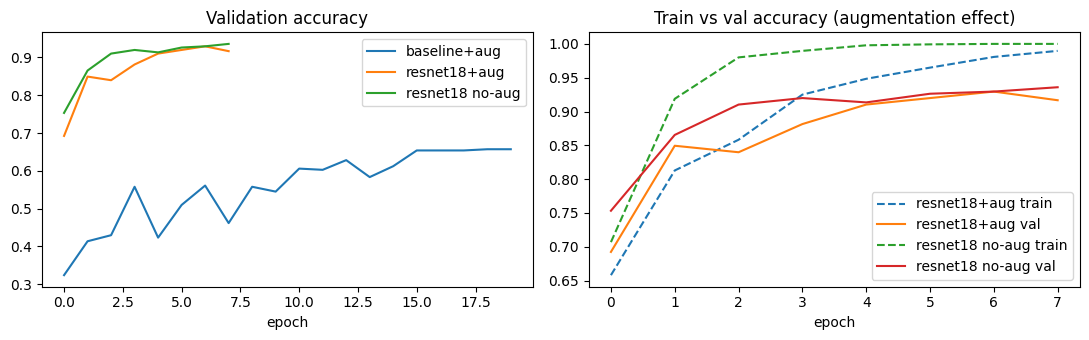

In [19]:
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
for name, h in [("baseline+aug", h_base), ("resnet18+aug", h_aug), ("resnet18 no-aug", h_plain)]:
    plt.plot(h["val_acc"], label=name)
plt.title("Validation accuracy"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
for name, h in [("resnet18+aug", h_aug), ("resnet18 no-aug", h_plain)]:
    plt.plot(h["train_acc"], "--", label=name + " train")
    plt.plot(h["val_acc"], label=name + " val")
plt.title("Train vs val accuracy (augmentation effect)"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.show()

## 9. Evaluation on the test set

In [21]:
@torch.no_grad()
def get_probs(model, loader):
    model.eval()
    Y, P = [], []
    for x, y in loader:
        P.append(torch.softmax(model(x.to(device)), 1).cpu())
        Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

def plot_cm(cm, title):
    plt.figure(figsize=(5.5, 5))
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
    plt.yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.show()

results = {}
for name, model in [("Baseline CNN + aug", baseline), ("ResNet18 + aug", resnet_aug), ("ResNet18 no aug", resnet_plain)]:
    y_true, probs = get_probs(model, test_loader)
    y_pred = probs.argmax(1)
    results[name] = dict(acc=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, average="macro"),
                         probs=probs, y_true=y_true)

print(f"{'Model':22s} {'Test acc':>9s} {'Macro-F1':>9s}")
for k, r in results.items():
    print(f"{k:22s} {r['acc']:9.3f} {r['f1']:9.3f}")

Model                   Test acc  Macro-F1
Baseline CNN + aug         0.654     0.640
ResNet18 + aug             0.888     0.875
ResNet18 no aug            0.920     0.920


=== ResNet18 + aug: test accuracy 0.8878 ===

              precision    recall  f1-score   support

   cardboard      0.978     0.898     0.936        49
       glass      0.829     0.935     0.879        62
       metal      0.904     0.855     0.879        55
       paper      0.905     0.918     0.912        73
     plastic      0.957     0.818     0.882        55
       trash      0.667     0.889     0.762        18

    accuracy                          0.888       312
   macro avg      0.873     0.885     0.875       312
weighted avg      0.897     0.888     0.889       312



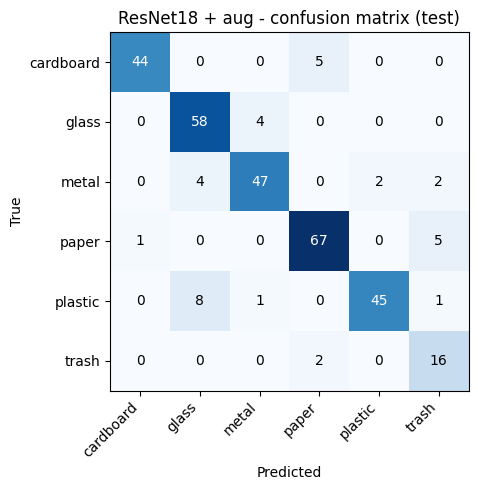

Per-class error rate (1 - recall):
  cardboard : 0.102  (5 of 49 wrong)
  glass     : 0.065  (4 of 62 wrong)
  metal     : 0.145  (8 of 55 wrong)
  paper     : 0.082  (6 of 73 wrong)
  plastic   : 0.182  (10 of 55 wrong)
  trash     : 0.111  (2 of 18 wrong)

=== Baseline CNN ===
              precision    recall  f1-score   support

   cardboard      0.830     0.796     0.812        49
       glass      0.655     0.581     0.615        62
       metal      0.533     0.436     0.480        55
       paper      0.803     0.726     0.763        73
     plastic      0.594     0.691     0.639        55
       trash      0.400     0.778     0.528        18

    accuracy                          0.654       312
   macro avg      0.636     0.668     0.640       312
weighted avg      0.670     0.654     0.656       312



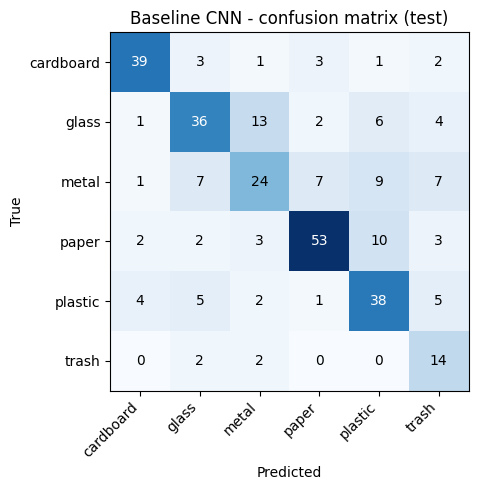

In [22]:
FINAL = "ResNet18 + aug"
y_true = results[FINAL]["y_true"]
probs = results[FINAL]["probs"]
y_pred = probs.argmax(1)

print(f"=== {FINAL}: test accuracy {accuracy_score(y_true, y_pred):.4f} ===\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
plot_cm(cm, f"{FINAL} - confusion matrix (test)")

print("Per-class error rate (1 - recall):")
for i, c in enumerate(CLASSES):
    print(f"  {c:10s}: {1 - cm[i, i] / cm[i].sum():.3f}  ({cm[i].sum() - cm[i, i]} of {cm[i].sum()} wrong)")

# baseline for comparison
yb = results["Baseline CNN + aug"]["probs"].argmax(1)
print("\n=== Baseline CNN ===")
print(classification_report(y_true, yb, target_names=CLASSES, digits=3))
plot_cm(confusion_matrix(y_true, yb, labels=range(len(CLASSES))), "Baseline CNN - confusion matrix (test)")

**Reading the results**

- *Transfer learning vs baseline:* ResNet18 starts from ImageNet features (edges, textures, shapes) so it needs far fewer images than a CNN trained from scratch on ~1.7k training images; compare the table above.
- *Augmentation effect:* look at the train-vs-val curves. Without augmentation, training accuracy reaches ~100% quickly and the gap to validation accuracy is larger (overfitting). Crops, flips, rotations and colour jitter make the model less dependent on exact framing, orientation and lighting. The test table above shows whether this translated into better generalisation in your run.

## 10. Failure cases and error analysis

35 misclassified of 312 test images

Most common confusions (true -> predicted):
  plastic -> glass: 8
  cardboard -> paper: 5
  paper -> trash: 5
  metal -> glass: 4
  glass -> metal: 4
  trash -> paper: 2


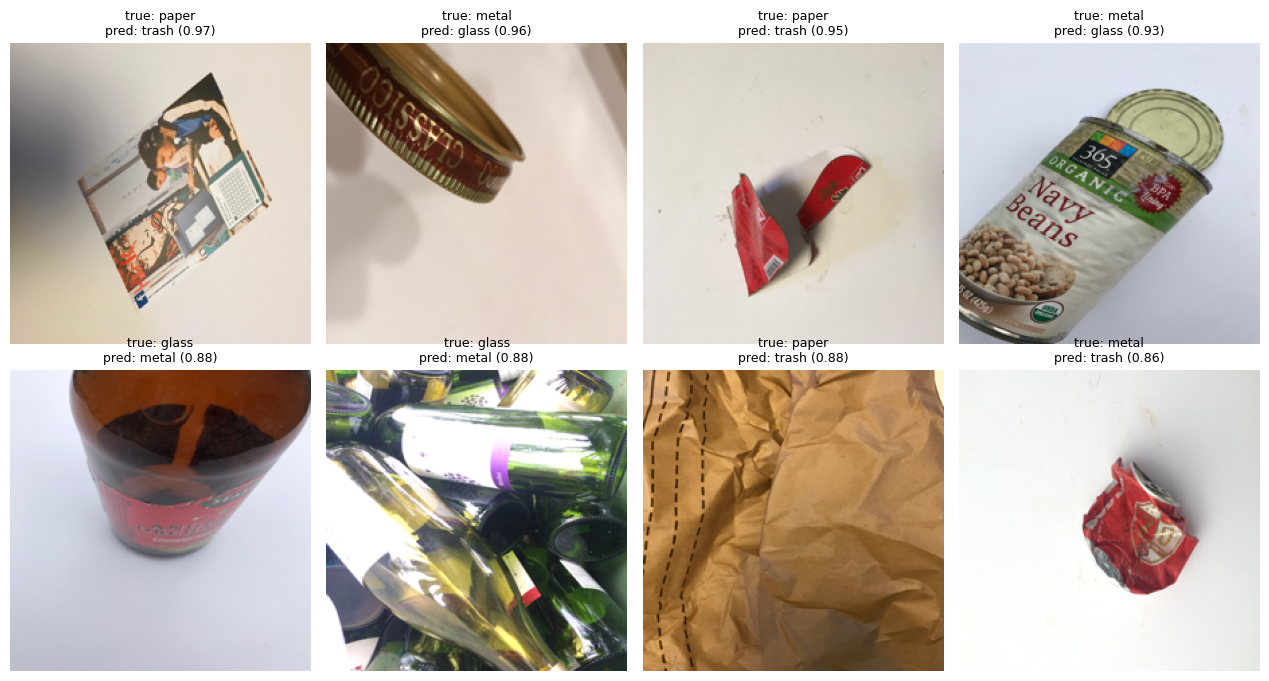

In [23]:
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} misclassified of {len(y_true)} test images")

# most frequent confusions
pairs = Counter((CLASSES[y_true[i]], CLASSES[y_pred[i]]) for i in wrong)
print("\nMost common confusions (true -> predicted):")
for (t, p), n in pairs.most_common(6):
    print(f"  {t} -> {p}: {n}")

# show the most CONFIDENT mistakes (the worst kind of failure)
order = wrong[np.argsort(-probs[wrong].max(1))][:8]
if len(order):
    cols = 4
    rows = int(np.ceil(len(order) / cols))
    plt.figure(figsize=(3.2 * cols, 3.4 * rows))
    for k, i in enumerate(order):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(images[test_idx[i]])      # test loader is not shuffled -> same order as test_idx
        plt.title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({probs[i].max():.2f})", fontsize=9)
        plt.axis("off")
    plt.tight_layout(); plt.show()

**Why the model gets these wrong (typical causes in TrashNet)**

- **Visually similar materials:** glass vs plastic (transparent, shiny, bottle-shaped) and paper vs cardboard (same fibre texture, differ mainly in thickness/colour) are the usual top confusions.
- **Metal reflections:** shiny cans mirror the background and can look like glass or plastic.
- **`trash` is a catch-all class with very few images:** it contains arbitrary objects, so it has no consistent visual pattern, and the model sees few examples of it.
- **Dataset bias:** TrashNet photos are single objects on a plain white background under similar lighting; crumpled, dirty, partly hidden or multiple items fall outside this distribution.
- **Squashing to 224x224:** original images are 4:3, so resizing distorts shapes slightly.

## 11. Confidence-threshold tuning

Idea: if the top softmax probability is below a threshold, return "uncertain" (e.g. ask a human) instead of guessing. The threshold is chosen on the **validation** set and then reported on the **test** set.

  thr |  val cov  val acc | test cov test acc
 0.30 |    1.000    0.929 |    1.000    0.888
 0.35 |    0.997    0.932 |    0.997    0.891
 0.40 |    0.997    0.932 |    0.990    0.896
 0.45 |    0.990    0.935 |    0.984    0.902
 0.50 |    0.971    0.941 |    0.981    0.902
 0.55 |    0.955    0.946 |    0.958    0.910
 0.60 |    0.949    0.946 |    0.955    0.909
 0.65 |    0.936    0.945 |    0.917    0.927
 0.70 |    0.929    0.945 |    0.904    0.933
 0.75 |    0.923    0.951 |    0.885    0.942
 0.80 |    0.901    0.954 |    0.862    0.948
 0.85 |    0.875    0.960 |    0.817    0.965
 0.90 |    0.833    0.969 |    0.760    0.983
 0.95 |    0.734    0.978 |    0.686    0.991

Chosen threshold (from validation): 0.75
Test set at this threshold: coverage 0.885, accuracy on accepted 0.942


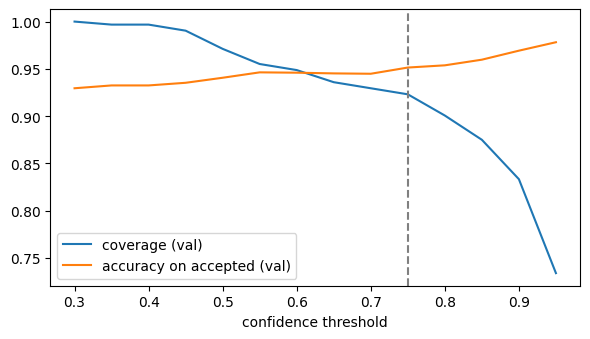

In [24]:
yv, pv = get_probs(resnet_aug, val_loader)
TARGET_ACC = 0.95

def sweep(y, p, thresholds):
    conf, pred = p.max(1), p.argmax(1)
    rows = []
    for t in thresholds:
        keep = conf >= t
        cov = keep.mean()
        acc = (pred[keep] == y[keep]).mean() if keep.any() else float("nan")
        rows.append((t, cov, acc))
    return rows

ths = np.round(np.arange(0.30, 1.00, 0.05), 2)
val_rows = sweep(yv, pv, ths)
test_rows = sweep(y_true, probs, ths)

print(f"{'thr':>5s} | {'val cov':>8s} {'val acc':>8s} | {'test cov':>8s} {'test acc':>8s}")
for (t, vc, va), (_, tc, ta) in zip(val_rows, test_rows):
    print(f"{t:5.2f} | {vc:8.3f} {va:8.3f} | {tc:8.3f} {ta:8.3f}")

# smallest threshold reaching the target accuracy on validation (max coverage)
ok = [r for r in val_rows if not np.isnan(r[2]) and r[2] >= TARGET_ACC]
BEST_T = float(ok[0][0]) if ok else 0.5
print(f"\nChosen threshold (from validation): {BEST_T}")
tr = [r for r in test_rows if abs(r[0] - BEST_T) < 1e-9][0]
print(f"Test set at this threshold: coverage {tr[1]:.3f}, accuracy on accepted {tr[2]:.3f}")

plt.figure(figsize=(6, 3.5))
plt.plot(ths, [r[1] for r in val_rows], label="coverage (val)")
plt.plot(ths, [r[2] for r in val_rows], label="accuracy on accepted (val)")
plt.axvline(BEST_T, color="gray", ls="--")
plt.xlabel("confidence threshold"); plt.legend(); plt.tight_layout(); plt.show()

## 12. Inference latency

In [25]:
def measure_latency(model, dev, n=100, warmup=10):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(1, 3, IMG, IMG, device=dev)
    times = []
    with torch.no_grad():
        for i in range(warmup + n):
            if dev.type == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter()
            m(x)
            if dev.type == "cuda": torch.cuda.synchronize()
            if i >= warmup:
                times.append((time.perf_counter() - t0) * 1000)
    return np.mean(times), np.percentile(times, 95)

devs = [torch.device("cpu")] + ([torch.device("cuda")] if torch.cuda.is_available() else [])
for name, mdl in [("Baseline CNN", baseline), ("ResNet18", resnet_aug)]:
    for d in devs:
        mean_ms, p95_ms = measure_latency(mdl, d)
        print(f"{name:13s} on {d.type:4s}: mean {mean_ms:6.1f} ms | p95 {p95_ms:6.1f} ms  (batch size 1, model only)")

Baseline CNN  on cpu : mean   18.5 ms | p95   19.5 ms  (batch size 1, model only)
Baseline CNN  on cuda: mean    1.2 ms | p95    1.2 ms  (batch size 1, model only)
ResNet18      on cpu : mean   30.2 ms | p95   32.4 ms  (batch size 1, model only)
ResNet18      on cuda: mean    3.1 ms | p95    3.9 ms  (batch size 1, model only)


## 13. Save model and create the inference script

In [26]:
torch.save({"state_dict": resnet_aug.cpu().state_dict(), "classes": CLASSES, "img_size": IMG,
            "threshold": BEST_T}, "trashnet_resnet18.pt")
resnet_aug.to(device)
print("Saved trashnet_resnet18.pt")

Saved trashnet_resnet18.pt


In [27]:
%%writefile predict.py
"""Usage: python predict.py image.jpg [threshold]"""
import sys
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models, transforms


def load_model(path="trashnet_resnet18.pt", device="cpu"):
    ckpt = torch.load(path, map_location=device)
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(ckpt["classes"]))
    model.load_state_dict(ckpt["state_dict"])
    model.to(device).eval()
    return model, ckpt["classes"], ckpt.get("threshold", 0.0), ckpt.get("img_size", 224)


def predict(image, model, classes, img_size=224, threshold=0.0, device="cpu"):
    """image: file path or PIL image. Returns dict with class, confidence, and all probabilities."""
    if isinstance(image, str):
        image = Image.open(image)
    image = image.convert("RGB")
    tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    with torch.no_grad():
        probs = torch.softmax(model(tf(image).unsqueeze(0).to(device)), dim=1)[0].cpu()
    conf, idx = probs.max(0)
    label = classes[idx.item()] if conf.item() >= threshold else "uncertain"
    return {"class": label, "top_class": classes[idx.item()], "confidence": round(conf.item(), 4),
            "probabilities": {c: round(p.item(), 4) for c, p in zip(classes, probs)}}


if __name__ == "__main__":
    path = sys.argv[1]
    model, classes, thr, size = load_model()
    if len(sys.argv) > 2:
        thr = float(sys.argv[2])
    print(predict(path, model, classes, size, thr))

Writing predict.py


## 14. Demo

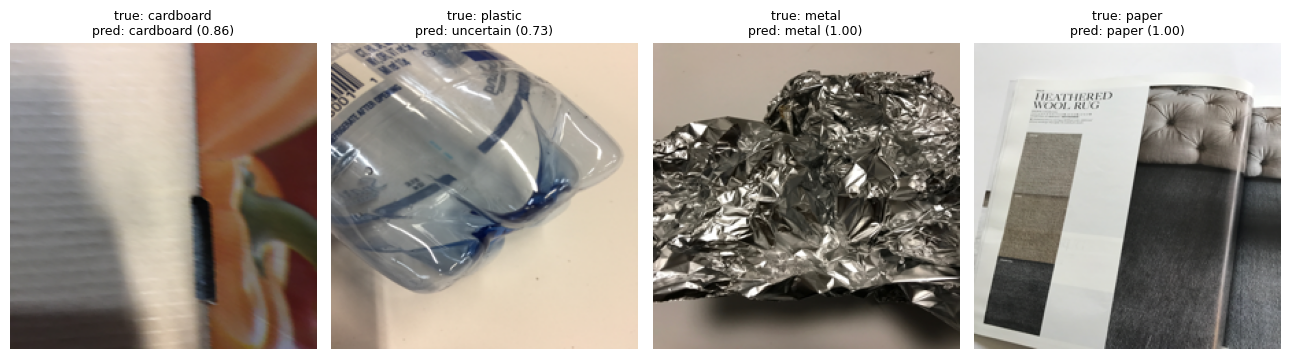

In [28]:
from predict import load_model, predict

model_i, classes_i, thr_i, size_i = load_model("trashnet_resnet18.pt", device="cpu")

# 4 random test images
rng = np.random.RandomState(0)
sample = rng.choice(len(test_idx), 4, replace=False)
plt.figure(figsize=(13, 3.6))
for k, i in enumerate(sample):
    img = images[test_idx[i]]
    out = predict(img, model_i, classes_i, size_i, thr_i)
    plt.subplot(1, 4, k + 1)
    plt.imshow(img); plt.axis("off")
    plt.title(f"true: {CLASSES[y_true[i]]}\npred: {out['class']} ({out['confidence']:.2f})", fontsize=9)
plt.tight_layout(); plt.show()

# Your own image: upload a file next to this notebook and uncomment
# print(predict("my_photo.jpg", model_i, classes_i, size_i, thr_i))
# or from a terminal:  python predict.py my_photo.jpg

## 15. Limitations for real campus waste

- **Domain gap:** TrashNet = one clean object on a white background. Campus bins have clutter, multiple items, food residue, bags, bad lighting and partial occlusion, so accuracy will be noticeably lower than the test numbers above.
- **Small and imbalanced:** ~2.5k images, `trash` is the smallest class. Test-set metrics from a few hundred images have wide error bars (one image = ~0.3 percentage points).
- **Missing categories:** no e-waste, organic/food waste, Tetra Pak, batteries, composite items (e.g. coffee cups with plastic lining), which are common on campus.
- **Single-label only:** the model assigns one class per image and has no detection, so it cannot handle several items in one photo.
- **Calibration:** softmax confidences from fine-tuned networks are often over-confident; use the threshold and "uncertain" route to a human, and ideally collect campus photos to fine-tune and re-calibrate.
- **Latency:** see section 12; ResNet18 is light enough for CPU or edge devices at interactive speed.